# RQ1 Step 3: Multi-output Ridge trajectory model

This notebook trains a leakage-safe learned benchmark using 24 hours of trajectory history to predict the complete subsequent 72-hour trajectory. Model selection uses training drifters only; calibration is reserved for later conformal inference, and the frozen model is evaluated once on 757 test cases.


## 1. Model definition

Each case has 98 inputs: origin latitude and longitude plus 24 hourly values of relative east displacement, relative north displacement, east velocity and north velocity. The 144 targets are east/north displacements for 72 future hours. Multi-output Ridge estimates all targets jointly with an L2 penalty.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/processed; open the notebook from the project directory or a notebook subdirectory.')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'en'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6_371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
ALPHAS = np.array([0.1, 1.0, 10.0, 100.0, 1_000.0, 10_000.0])
N_FOLDS = 5

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Project directory: ', PROJECT_ROOT.resolve())
print('Output directory: ', OUTPUT_DIR.resolve())

Project directory:  /Users/roger/Documents/data3001-project-main
Output directory:  /Users/roger/Documents/data3001-project-main/output/rq1/en


## 2. Convert spherical positions and local displacements

Targets are expressed as east/north displacement from the forecast origin in kilometres. Helper functions convert between these local coordinates and latitude/longitude for geographic evaluation.


In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0

    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central_angle = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance_km = EARTH_RADIUS_KM * central_angle
    east_km = distance_km * np.sin(bearing)
    north_km = distance_km * np.cos(bearing)
    return east_km, north_km


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM

    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

## 3. Read fixed cases and construct 24-hour inputs

Every fixed case contributes exactly 24 historical observations. Cases are ordered by forecast-case ID and no partition is resampled.


In [3]:
origins = (
    pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
    .sort_values('forecast_case_id').reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
)
n_cases = len(origins)

history = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'history_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history['history_index'] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history['segment_step'] = history['history_start_step'] + history['history_index']
history = history.merge(
    observations,
    on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'history_index']).reset_index(drop=True)

history['relative_east_km'], history['relative_north_km'] = latlon_to_local_km(
    history['origin_latitude'], history['origin_longitude'],
    history['latitude'], history['longitude'],
)

history_values = history[[
    'relative_east_km', 'relative_north_km', 've', 'vn',
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)

X = np.column_stack([
    origins['origin_latitude'].to_numpy(),
    origins['origin_longitude'].to_numpy(),
    history_values.reshape(n_cases, -1),
])

history_checks = pd.Series({
    'There are 5,117 cases': n_cases == 5117,
    'Every case has exactly 24 historical observations': history.groupby('forecast_case_id').size().eq(24).all(),
    'Input matrix has shape 5117 x 98': X.shape == (5117, 98),
    'Inputs contain no missing or infinite values': np.isfinite(X).all(),
}, name='Passed')
display(history_checks.to_frame())
assert history_checks.all()

,Passed
"There are 5,117 cases",True
Every case has exactly 24 historical observations,True
Input matrix has shape 5117 x 98,True
Inputs contain no missing or infinite values,True


## 4. Construct 72-hour targets

Each observed future trajectory is converted into 72 pairs of east/north displacement, producing a 5,117 by 144 target matrix.


In [4]:
targets = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'target_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(
    observations[['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude']],
    on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'lead_time_hours']).reset_index(drop=True)

targets['target_east_km'], targets['target_north_km'] = latlon_to_local_km(
    targets['origin_latitude'], targets['origin_longitude'],
    targets['latitude'], targets['longitude'],
)
target_displacements = targets[['target_east_km', 'target_north_km']].to_numpy()
Y = target_displacements.reshape(n_cases, HORIZON_HOURS * 2)

target_checks = pd.Series({
    'Every case has exactly 72 future observations': targets.groupby('forecast_case_id').size().eq(72).all(),
    'Target matrix has shape 5117 x 144': Y.shape == (5117, 144),
    'Targets contain no missing or infinite values': np.isfinite(Y).all(),
}, name='Passed')
display(target_checks.to_frame())
assert target_checks.all()

,Passed
Every case has exactly 72 future observations,True
Target matrix has shape 5117 x 144,True
Targets contain no missing or infinite values,True


## 5. Grouped five-fold cross-validation within training drifters

All cases from one drifter remain in the same fold. Calibration and test cases do not participate in selecting the Ridge penalty.


In [5]:
train_indices = np.flatnonzero(origins['partition'].eq('training').to_numpy())
calibration_indices = np.flatnonzero(origins['partition'].eq('calibration').to_numpy())
test_indices = np.flatnonzero(origins['partition'].eq('test').to_numpy())

training_group_counts = (
    origins.loc[train_indices].groupby('ID').size().sort_values(ascending=False)
)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_case_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_case_counts))
    fold_drifters[fold].append(drifter_id)
    fold_case_counts[fold] += int(count)

fold_summary = pd.DataFrame({
    'Fold': np.arange(1, N_FOLDS + 1),
    'Training drifters held out': [len(x) for x in fold_drifters],
    'Validation cases': fold_case_counts,
})
display(fold_summary)

assert len(train_indices) == 3591
assert len(calibration_indices) == 769
assert len(test_indices) == 757
assert fold_case_counts.sum() == len(train_indices)

,Fold,Training drifters held out,Validation cases
0,1,63,719
1,2,62,718
2,3,62,718
3,4,62,718
4,5,62,718


## 6. Fit and select Multi-output Ridge

Feature scaling is estimated separately within each training fold. The penalty is selected by mean validation displacement RMSE across the five grouped folds.


In [6]:
def fit_ridge(X_train, Y_train, alpha):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)

    X_standard = (X_train - x_mean) / x_scale
    gram = X_standard.T @ X_standard
    coefficients = np.linalg.solve(
        gram + alpha * np.eye(gram.shape[0]),
        X_standard.T @ (Y_train - y_mean),
    )
    return {
        'alpha': float(alpha),
        'x_mean': x_mean,
        'x_scale': x_scale,
        'y_mean': y_mean,
        'coefficients': coefficients,
    }


def predict_ridge(model, X_new):
    X_standard = (X_new - model['x_mean']) / model['x_scale']
    return X_standard @ model['coefficients'] + model['y_mean']


cv_rows = []
for alpha in ALPHAS:
    for fold_number, validation_drifters in enumerate(fold_drifters, start=1):
        is_validation = origins.loc[train_indices, 'ID'].isin(validation_drifters).to_numpy()
        fold_validation_indices = train_indices[is_validation]
        fold_training_indices = train_indices[~is_validation]

        fold_model = fit_ridge(X[fold_training_indices], Y[fold_training_indices], alpha)
        fold_predictions = predict_ridge(fold_model, X[fold_validation_indices])
        displacement_rmse = np.sqrt(np.mean(
            np.square(fold_predictions - Y[fold_validation_indices])
        ))
        cv_rows.append({
            'alpha': alpha,
            'fold': fold_number,
            'validation_cases': len(fold_validation_indices),
            'displacement_rmse_km': displacement_rmse,
        })

cv_folds = pd.DataFrame(cv_rows)
cv_results = (
    cv_folds.groupby('alpha')['displacement_rmse_km']
    .agg(mean_cv_rmse_km='mean', std_cv_rmse_km='std')
    .reset_index()
)
best_alpha = float(cv_results.loc[cv_results['mean_cv_rmse_km'].idxmin(), 'alpha'])
display(cv_results.round(3))
print(f'Selected alpha: {best_alpha:g}')

,alpha,mean_cv_rmse_km,std_cv_rmse_km
0,0.1,28.077,1.279
1,1.0,27.945,1.263
2,10.0,27.791,1.294
3,100.0,27.668,1.386
4,1000.0,27.950,1.514
5,10000.0,28.763,1.676


Selected alpha: 100


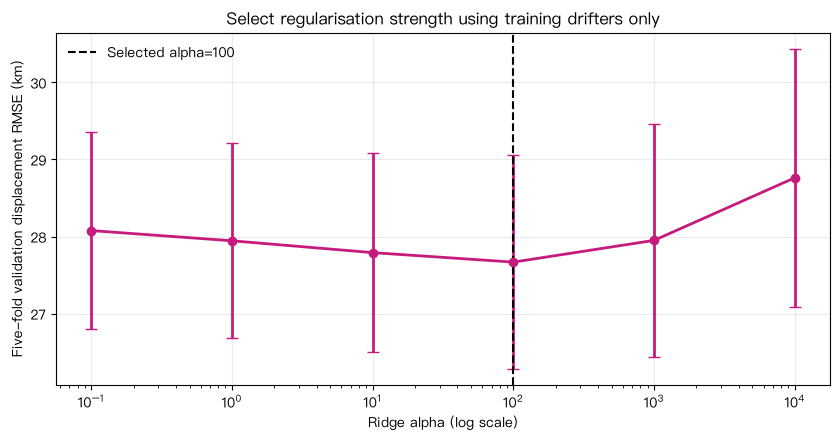

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.errorbar(
    cv_results['alpha'], cv_results['mean_cv_rmse_km'],
    yerr=cv_results['std_cv_rmse_km'], marker='o', capsize=4,
    linewidth=2, color='#c51b7d',
)
ax.axvline(best_alpha, color='black', linestyle='--', linewidth=1.5,
           label=f'Selected alpha={best_alpha:g}')
ax.set_xscale('log')
ax.set(
    xlabel='Ridge alpha (log scale)', ylabel='Five-fold validation displacement RMSE (km)',
    title='Select regularisation strength using training drifters only',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ridge_cross_validation.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Fit the final model on all training cases

After selecting the penalty, Ridge is refitted on all 3,591 training cases and frozen before predicting the 757 test cases. Calibration remains unused.


In [8]:
final_model = fit_ridge(X[train_indices], Y[train_indices], best_alpha)
test_predictions = predict_ridge(final_model, X[test_indices]).reshape(
    len(test_indices), HORIZON_HOURS, 2
)

test_origins = origins.loc[test_indices].reset_index(drop=True)
origin_latitudes = np.repeat(test_origins['origin_latitude'].to_numpy(), HORIZON_HOURS)
origin_longitudes = np.repeat(test_origins['origin_longitude'].to_numpy(), HORIZON_HOURS)
predicted_latitude, predicted_longitude = local_km_to_latlon(
    origin_latitudes,
    origin_longitudes,
    test_predictions[:, :, 0].reshape(-1),
    test_predictions[:, :, 1].reshape(-1),
)

test_target_mask = targets['forecast_case_id'].isin(test_origins['forecast_case_id'])
test_targets = (
    targets.loc[test_target_mask]
    .sort_values(['forecast_case_id', 'lead_time_hours'])
    .reset_index(drop=True)
)

evaluation = pd.DataFrame({
    'forecast_case_id': np.repeat(test_origins['forecast_case_id'].to_numpy(), HORIZON_HOURS),
    'ID': np.repeat(test_origins['ID'].to_numpy(), HORIZON_HOURS),
    'lead_time_hours': np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
    'origin_latitude': origin_latitudes,
    'origin_longitude': origin_longitudes,
    'predicted_east_km': test_predictions[:, :, 0].reshape(-1),
    'predicted_north_km': test_predictions[:, :, 1].reshape(-1),
    'pred_latitude': predicted_latitude,
    'pred_longitude': predicted_longitude,
    'true_latitude': test_targets['latitude'].to_numpy(),
    'true_longitude': test_targets['longitude'].to_numpy(),
})
evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    'Evaluate only 757 test cases': evaluation['forecast_case_id'].nunique() == 757,
    'Every test case has exactly 72 lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
    'All errors are finite': np.isfinite(evaluation['separation_error_km']).all(),
    'Calibration cases remain unused for fitting': len(calibration_indices) == 769,
}, name='Passed')
display(checks.to_frame())
assert checks.all()

,Passed
Evaluate only 757 test cases,True
Every test case has exactly 72 lead times,True
All errors are finite,True
Calibration cases remain unused for fitting,True


## 8. Held-out test error by lead time

Report median, mean, interquartile range and RMSE using the same geographic separation error as the baselines.


,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.18,0.29,0.11,0.33,0.49
5,6,757,2.52,2.99,1.45,3.72,3.82
11,12,757,5.70,6.99,3.33,8.77,8.92
23,24,757,12.32,15.03,7.15,19.63,18.97
47,48,757,28.27,34.65,17.21,45.69,42.59
71,72,757,44.75,54.23,27.28,70.16,65.91


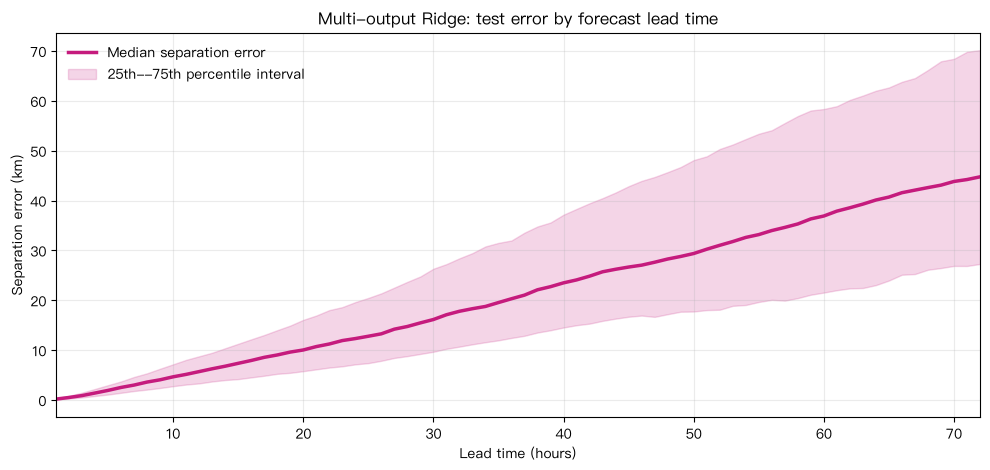

In [9]:
lead_metrics = (
    evaluation.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size',
        median_error_km='median',
        mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    )
    .reset_index()
)
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#c51b7d', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#c51b7d', alpha=0.18, label='25th--75th percentile interval')
ax.set(
    xlabel='Lead time (hours)', ylabel='Separation error (km)',
    title='Multi-output Ridge: test error by forecast lead time',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ridge_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. Fair comparison with both baselines

Forecast skill is calculated from RMSE on identical test cases. Positive skill means Ridge improves on the corresponding baseline.


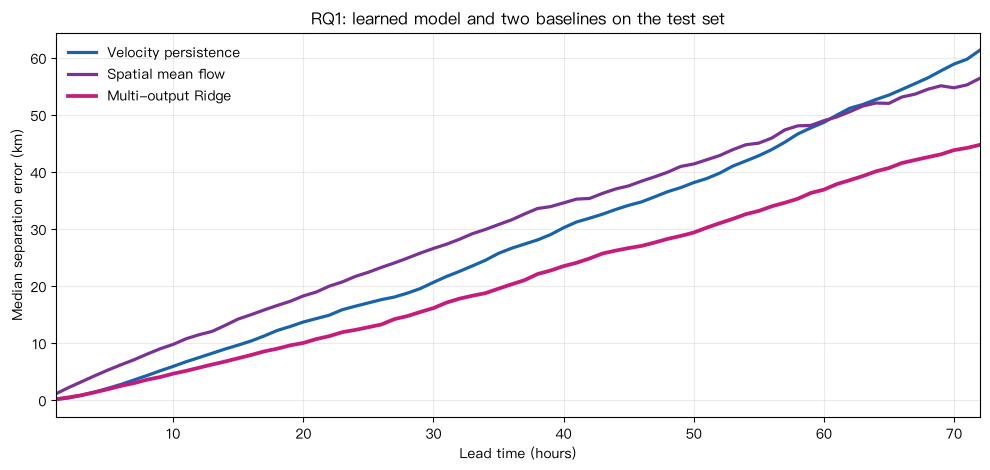

,ridge_median_km,persistence_median_km,mean_flow_median_km,ridge_rmse_km,persistence_rmse_km,mean_flow_rmse_km,ridge_rmse_minus_persistence_km,ridge_rmse_minus_mean_flow_km,skill_vs_persistence_pct,skill_vs_mean_flow_pct
lead_time_hours,,,,,,,,,,
24,12.32,16.47,21.69,18.97,24.07,29.87,-5.10,-10.89,21.17,36.47
48,28.27,36.54,39.96,42.59,55.17,57.27,-12.58,-14.68,22.81,25.64
72,44.75,61.35,56.42,65.91,90.10,80.98,-24.19,-15.07,26.85,18.60


In [10]:
persistence_metrics = pd.read_csv(OUTPUT_DIR / 'velocity_persistence_lead_metrics.csv')
mean_flow_metrics = pd.read_csv(OUTPUT_DIR / 'spatial_mean_flow_lead_metrics.csv')

comparison = (
    lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']]
    .rename(columns={
        'median_error_km': 'ridge_median_km',
        'rmse_km': 'ridge_rmse_km',
    })
    .merge(
        persistence_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': 'persistence_median_km',
            'rmse_km': 'persistence_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
    .merge(
        mean_flow_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': 'mean_flow_median_km',
            'rmse_km': 'mean_flow_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
)
comparison['ridge_rmse_minus_persistence_km'] = (
    comparison['ridge_rmse_km'] - comparison['persistence_rmse_km']
)
comparison['ridge_rmse_minus_mean_flow_km'] = (
    comparison['ridge_rmse_km'] - comparison['mean_flow_rmse_km']
)
comparison['skill_vs_persistence_pct'] = 100 * (
    1 - comparison['ridge_rmse_km'] / comparison['persistence_rmse_km']
)
comparison['skill_vs_mean_flow_pct'] = 100 * (
    1 - comparison['ridge_rmse_km'] / comparison['mean_flow_rmse_km']
)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(comparison['lead_time_hours'], comparison['persistence_median_km'],
        linewidth=2.3, color='#1764ab', label='Velocity persistence')
ax.plot(comparison['lead_time_hours'], comparison['mean_flow_median_km'],
        linewidth=2.3, color='#7b3294', label='Spatial mean flow')
ax.plot(comparison['lead_time_hours'], comparison['ridge_median_km'],
        linewidth=2.7, color='#c51b7d', label='Multi-output Ridge')
ax.set(
    xlabel='Lead time (hours)', ylabel='Median separation error (km)',
    title='RQ1: learned model and two baselines on the test set',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq1_three_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

comparison_table = comparison.loc[
    comparison['lead_time_hours'].isin([24, 48, 72]),
    [
        'lead_time_hours',
        'ridge_median_km', 'persistence_median_km', 'mean_flow_median_km',
        'ridge_rmse_km', 'persistence_rmse_km', 'mean_flow_rmse_km',
        'ridge_rmse_minus_persistence_km', 'ridge_rmse_minus_mean_flow_km',
        'skill_vs_persistence_pct', 'skill_vs_mean_flow_pct',
    ],
].set_index('lead_time_hours')
display(comparison_table.round(2))

## 10. Case-level integrated trajectory error and final summary

ITE captures accumulated trajectory error over 72 hours. The summary also reports headline endpoint errors and RMSE.


In [11]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = evaluation.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    'Metric': [
        'Selected alpha', 'Training cases', 'Calibration cases (unused)', 'Test cases',
        '24h median error (km)', '48h median error (km)', '72h median error (km)',
        '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    'Value': [
        best_alpha, len(train_indices), len(calibration_indices), len(test_indices),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary.round(2))

,Metric,Value
0,Selected alpha,100.00
1,Training cases,3591.00
2,Calibration cases (unused),769.00
3,Test cases,757.00
4,24h median error (km),12.32
5,48h median error (km),28.27
6,72h median error (km),44.75
7,72h RMSE (km),65.91
8,Median ITE (km·h),1531.79


## 11. Representative trajectory

The displayed case has a 72-hour endpoint error closest to the test median.


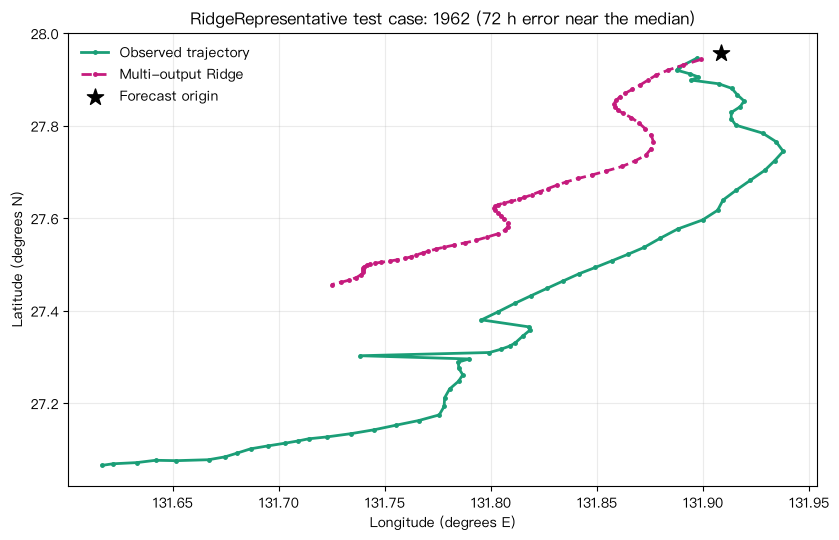

In [12]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = evaluation[evaluation['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
        linewidth=2, color='#1b9e77', label='Observed trajectory')
ax.plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
        linewidth=2, color='#c51b7d', label='Multi-output Ridge')
ax.scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
           marker='*', s=150, color='black', label='Forecast origin', zorder=5)
ax.set(
    xlabel='Longitude (degrees E)', ylabel='Latitude (degrees N)',
    title=f'RidgeRepresentative test case: {int(example_id)} (72 h error near the median)',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ridge_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 12. Save reproducible results

Save cross-validation results, fitted parameters, held-out metrics, comparisons and figures.


In [13]:
cv_folds.to_csv(OUTPUT_DIR / 'ridge_cross_validation_folds.csv', index=False)
cv_results.to_csv(OUTPUT_DIR / 'ridge_cross_validation_summary.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'ridge_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'ridge_test_case_metrics.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'rq1_three_model_comparison.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'ridge_summary.csv', index=False)

np.savez_compressed(
    OUTPUT_DIR / 'ridge_model_parameters.npz',
    alpha=final_model['alpha'],
    x_mean=final_model['x_mean'],
    x_scale=final_model['x_scale'],
    y_mean=final_model['y_mean'],
    coefficients=final_model['coefficients'],
)

saved_files = sorted(
    [p.name for p in OUTPUT_DIR.glob('ridge_*')]
    + [p.name for p in OUTPUT_DIR.glob('rq1_three_model_*')]
)
print('Saved:')
for name in saved_files:
    print(' -', name)

Saved:
 - ridge_cross_validation.png
 - ridge_cross_validation_folds.csv
 - ridge_cross_validation_summary.csv
 - ridge_error_curve.png
 - ridge_example_trajectory.png
 - ridge_lead_metrics.csv
 - ridge_model_parameters.npz
 - ridge_summary.csv
 - ridge_test_case_metrics.csv
 - rq1_three_model_comparison.csv
 - rq1_three_model_comparison.png
